<div style="background:linear-gradient(112deg,#0a2431,#146477);padding:32px 36px;border-radius:18px;color:white">
  <div style="text-transform:uppercase;letter-spacing:2.8px;font-size:12px;color:#b1e3ea"></div>
  <h1 style="margin:12px 0 12px 0;color:white;font-size:32px;font-weight:760">Point Cloud Streaming with Latency-Driven Adaptation</h1>
  <div style="font-size:16px;color:#e3f4f7"></div>
  <div style="font-size:13px;color:#bbdfe4;margin-top:19px"></div>
</div>

### **Demo Prepared by: Abdullah Al Noman**


**The question:** When two viewers have different tolerance for delay, how much of the **same 3D video** can each receive?

This notebook uses recorded frames from the **Microsoft Voxelized Upper Bodies (MVUB) `andrew9`** sequence. It independently compresses pieces of each frame with **Draco**, models delivery over a congested link, and reconstructs each frame from the pieces delivered on time.

> **Scope:** Real dataset and Draco encoding/decoding; **simulated** network transport and delivery deadlines.

## The idea

**Record a 3D frame → split it into independent pieces → compress each piece → deliver what fits before the deadline → reconstruct from whatever arrived.**

A shorter deadline generally preserves less 3D detail. A longer deadline can allow more pieces to arrive, but the viewer must tolerate additional delay.

**Connection to the paper:** Fig. 1 and Sections 3.1–3.4. Unlike a player that chooses a quality setting, the model makes delivery decisions using time, link capacity, and encoded object sizes.

## 1. Prepare the tools

I use **DracoPy**, a Python interface to Google's actual Draco codec. It produces real Draco-encoded byte streams (`.drc`)

The only dataset input is the `andrew9.zip` archive in the Google Drive.

In [1]:
%pip -q install "DracoPy>=1.4" "plyfile>=1.1" plotly

In [2]:
import io
import re
import time
import zipfile
from pathlib import Path
from collections import deque
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import DracoPy
from plyfile import PlyData
from IPython.display import display

ZIP_PATH = Path("/content/drive/MyDrive/Colab Notebooks/CSI5353/andrew9.zip")
FRAME_COUNT = 16
FRAME_STEP = 1 # consecutive real recorded frames
MAX_POINTS_PER_FRAME = 50_000 # real points; limits processing time only
FRAMES_PER_SECOND = 20
TRACKS = 10
FRAMES_PER_GROUP = 5
DEADLINES_MS = (50, 100, 500)
RANDOM_SEED = 5353
DRACO_COMPRESSION_LEVEL = 5
EXPORT_DIRECTORY = Path("/content/andrew9_draco_output")

OCEAN = "#137b83"
INK = "#18384a"
ORANGE = "#e18b4d"

try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError("Open this notebook in Google Colab to mount Google Drive.") from exc

if not ZIP_PATH.exists():
    drive.mount("/content/drive", force_remount=False)

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"Archive not found: {ZIP_PATH}\n"
        "Verify the ZIP is saved at this exact location in Google Drive."
    )

if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError(f"The file exists but is not a valid ZIP archive: {ZIP_PATH}")

print("Source archive:", ZIP_PATH)
print(f"Archive size: {ZIP_PATH.stat().st_size / 1e9:.2f} GB")
print("Dataset policy: real Andrew9 frames only")

Mounted at /content/drive
Source archive: /content/drive/MyDrive/Colab Notebooks/CSI5353/andrew9.zip
Archive size: 0.51 GB
Dataset policy: real Andrew9 frames only


## 2. Load the recorded frames

Each PLY file contains a captured 3D frame with point positions and colors. I read a short, consecutive excerpt directly from the ZIP, so the entire archive does not need to be extracted.

In [3]:
def frame_number(filename):
    stem = Path(filename).stem
    digits = re.findall(r"\d+", stem)
    return int(digits[-1]) if digits else -1

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    all_ply_names = [info.filename for info in archive.infolist()
                     if not info.is_dir() and info.filename.lower().endswith(".ply")]
    all_ply_names = sorted(all_ply_names, key=lambda s: (frame_number(s), s.lower()))

if len(all_ply_names) < FRAME_COUNT * FRAME_STEP:
    with zipfile.ZipFile(ZIP_PATH) as archive:
        sample_members = [x.filename for x in archive.infolist()[:12]]
    raise RuntimeError(
        f"Expected at least {FRAME_COUNT * FRAME_STEP} PLY frames, found "
        f"{len(all_ply_names)}. First ZIP members: {sample_members}"
    )

selected_names = all_ply_names[::FRAME_STEP][:FRAME_COUNT]

def read_frame_from_zip(archive, name, seed):
    with archive.open(name) as fp:
        ply = PlyData.read(io.BytesIO(fp.read()))
    if not any(element.name == "vertex" for element in ply.elements):
        raise ValueError(f"No vertex table in {name}")

    vertex = ply["vertex"].data
    fields = set(vertex.dtype.names or [])
    if not {"x", "y", "z"}.issubset(fields):
        raise ValueError(f"Missing x/y/z coordinates in {name}: {sorted(fields)}")

    coords = np.column_stack([vertex[k] for k in ("x","y","z")]).astype(np.float64)
    color_sets = [
        ("red", "green", "blue"),
        ("r", "g", "b"),
        ("diffuse_red", "diffuse_green", "diffuse_blue"),
    ]
    color_keys = next((keys for keys in color_sets if set(keys).issubset(fields)), None)
    if color_keys is None:
        raise ValueError(f"No recorded RGB colors found in {name}: {sorted(fields)}")

    rgb = np.column_stack([vertex[k] for k in color_keys])
    if rgb.dtype.kind == "f" and np.nanmax(rgb) <= 1.0:
        rgb = rgb * 255
    rgb = np.rint(np.clip(rgb, 0, 255)).astype(np.uint8)

    keep = np.isfinite(coords).all(axis=1)
    coords, rgb = coords[keep], rgb[keep]
    if len(coords) < TRACKS * 4:
        raise ValueError(f"Too few valid points in {name}: {len(coords)}")

    # subset, when necessary, is sampled from the original recording
    if len(coords) > MAX_POINTS_PER_FRAME:
        chosen = np.random.default_rng(seed).choice(
            len(coords), MAX_POINTS_PER_FRAME, replace=False)
        coords, rgb = coords[chosen], rgb[chosen]
    return np.ascontiguousarray(coords), np.ascontiguousarray(rgb)

FRAMES = []
load_start = time.perf_counter()
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for i, filename in enumerate(selected_names):
        FRAMES.append(read_frame_from_zip(archive, filename, RANDOM_SEED+i))
        if i in (0, len(selected_names)//2, len(selected_names)-1):
            print(f"Frame {i:02d}: {len(FRAMES[-1][0]):,} real points | {Path(filename).name}")

N_FRAMES = len(FRAMES)
point_sizes = np.array([len(xyz) for xyz, _ in FRAMES])
all_span = np.ptp(FRAMES[N_FRAMES//2][0], axis=0)
VERTICAL_AXIS = int(np.argmax(all_span))
HORIZONTAL_AXIS = int(next(axis for axis in np.argsort(all_span)[::-1]
                           if axis != VERTICAL_AXIS))
DEPTH_AXIS = next(i for i in range(3)
                  if i not in (VERTICAL_AXIS, HORIZONTAL_AXIS))

print(f"\nVerified: {N_FRAMES} consecutive recorded frames")
print(f"Points per frame: {point_sizes.min():,}–{point_sizes.max():,}")
print(f"Load time: {time.perf_counter()-load_start:.1f} s")
print("3D coordinate ranges:", np.round(np.min(FRAMES[0][0],axis=0),2),
      "to", np.round(np.max(FRAMES[0][0],axis=0),2))

Frame 00: 50,000 real points | frame0000.ply
Frame 08: 50,000 real points | frame0008.ply
Frame 15: 50,000 real points | frame0015.ply

Verified: 16 consecutive recorded frames
Points per frame: 50,000–50,000
Load time: 21.2 s
3D coordinate ranges: [ 20. 173.   0.] to [342. 419. 369.]


## 3. Look at the original 3D capture

This is recorded Andrew9 geometry, displayed with its original colors. Rotate the view with mouse.

In [4]:
VIEW_FRAME = N_FRAMES // 2
original_xyz, original_rgb = FRAMES[VIEW_FRAME]

show_idx = np.random.default_rng(12).choice(
    len(original_xyz), min(23_000, len(original_xyz)), replace=False)
show_xyz, show_rgb = original_xyz[show_idx], original_rgb[show_idx]
show_colors = [f"rgb({r},{g},{b})" for r,g,b in show_rgb]

figure = go.Figure(go.Scatter3d(
    x=show_xyz[:,0], y=show_xyz[:,1], z=show_xyz[:,2],
    mode="markers",
    marker=dict(size=1.9, opacity=0.88, color=show_colors),
    hoverinfo="skip"
))
figure.update_layout(
    title=f"Andrew9 · Recorded frame {VIEW_FRAME} · {len(original_xyz):,} retained points",
    height=570, margin=dict(l=0,r=0,t=60,b=0),
    scene=dict(aspectmode="data",
               xaxis=dict(visible=False),
               yaxis=dict(visible=False),
               zaxis=dict(visible=False)),
    paper_bgcolor="#ffffff"
)
figure.show()

## 4. Create independently usable pieces

A 3D frame is divided into **10 non-overlapping pieces**. Each piece contains a different random subset of the recorded points. A viewer can rebuild a useful, partial frame from *any* pieces that arrive.

This follows the paper's **multiple-description** approach: no piece requires a particular earlier piece in order to be decoded.

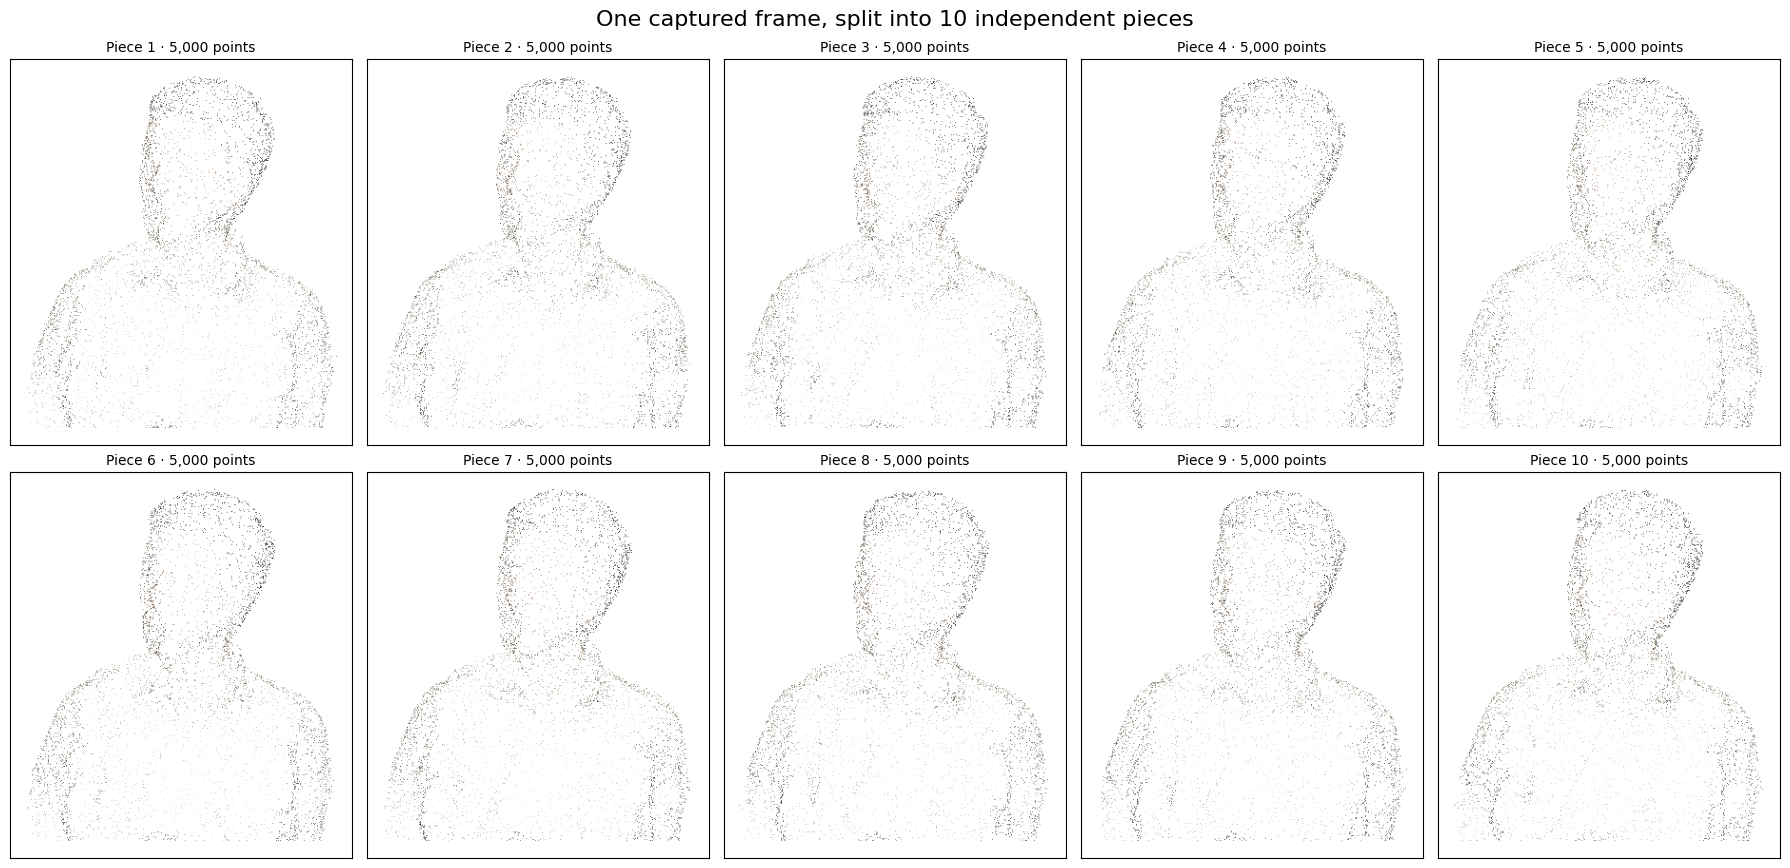

In [5]:
def split_frame(xyz, rgb, frame_id, salient_first=False):
    rng = np.random.default_rng(RANDOM_SEED + 10_000 + frame_id)
    if salient_first:
        # a transparent geometric proxy
        threshold = np.quantile(xyz[:, VERTICAL_AXIS], 0.82)
        head = np.flatnonzero(xyz[:, VERTICAL_AXIS] >= threshold)
        other = np.flatnonzero(xyz[:, VERTICAL_AXIS] < threshold)
        indices = np.concatenate([rng.permutation(head), rng.permutation(other)])
    else:
        indices = rng.permutation(len(xyz))
    return [np.asarray(part, dtype=np.int64)
            for part in np.array_split(indices, TRACKS)]

RANDOM_INDEX_PARTITIONS = [
    split_frame(xyz, rgb, i) for i, (xyz, rgb) in enumerate(FRAMES)
]

assert all(
    len(np.unique(np.concatenate(parts))) == len(FRAMES[i][0])
    for i, parts in enumerate(RANDOM_INDEX_PARTITIONS)
)
assert all(
    sum(map(len, parts)) == len(FRAMES[i][0])
    for i, parts in enumerate(RANDOM_INDEX_PARTITIONS)
)

demo_parts = RANDOM_INDEX_PARTITIONS[VIEW_FRAME]

fig, axs = plt.subplots(
    2, 5,
    figsize=(18, 9),
    sharex=True,
    sharey=True
)

for track, ax in enumerate(axs.flat):
    ids = demo_parts[track]
    xyz, rgb = FRAMES[VIEW_FRAME]

    ax.scatter(
        xyz[ids, HORIZONTAL_AXIS],
        xyz[ids, VERTICAL_AXIS],
        s=0.35,
        c=rgb[ids] / 255,
        linewidths=0
    )
    ax.set_title(f"Piece {track+1} · {len(ids):,} points", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
fig.suptitle("One captured frame, split into 10 independent pieces", fontsize=16)
plt.tight_layout(); plt.show()

## 5. Compress each piece using **Draco**

Every piece is encoded into its own Draco byte stream. These compressed bytes are what the delivery model will transmit.

**Coordinate precision:** Each point cloud is encoded using 32-bit floating-point coordinates with Draco position quantization disabled, following the paper's approach. Each partition is compressed and decoded independently.

Draco encoding happens ahead of the simulated transmission. The paper encodes partitions in parallel; this notebook encodes them sequentially to keep the demonstration straightforward.

In [6]:
def integer_voxel_coordinates(frames):
    for xyz, _ in frames:
        if not np.allclose(xyz, np.rint(xyz), atol=1e-6, rtol=0):
            return False
        if np.max(np.abs(xyz)) > 2_000_000_000:
            return False
    return True

INTEGER_VOXELS = integer_voxel_coordinates(FRAMES)
POSITION_MODE = "Float32 coordinates with position quantization disabled"
print("Draco coordinate mode:", POSITION_MODE)

@dataclass(frozen=True)
class EncodedObject:
    frame: int
    track: int
    group: int
    published_at: float
    data: bytes
    npoints: int
    upper_points: int
    @property
    def nbytes(self):
        return len(self.data)

def draco_encode(xyz, colors):
    xyz_in = np.ascontiguousarray(xyz, dtype=np.float32)

    return bytes(
        DracoPy.encode(
            xyz_in,
            colors=np.ascontiguousarray(colors, dtype=np.uint8),
            compression_level=DRACO_COMPRESSION_LEVEL,
            preserve_order=True,
            quantization_bits=0
        )
    )

def draco_decode(payload):
    pc = DracoPy.decode(payload)
    xyz = np.asarray(pc.points)
    colors = np.asarray(pc.colors) if pc.colors is not None else None
    if colors is None or colors.shape != (len(xyz),3):
        raise RuntimeError("The decoded Draco object is missing its RGB colors.")
    return xyz.astype(np.float64), colors.astype(np.uint8)

def encode_sequence(index_partitions):
    encoded = []
    encode_seconds = []
    for frame_id, indices_per_track in enumerate(index_partitions):
        xyz, rgb = FRAMES[frame_id]
        upper_cutoff = np.quantile(xyz[:, VERTICAL_AXIS], 0.82)
        for track, indices in enumerate(indices_per_track):
            start = time.perf_counter()
            payload = draco_encode(xyz[indices], rgb[indices])
            encode_seconds.append(time.perf_counter() - start)
            encoded.append(EncodedObject(
                frame=frame_id, track=track,
                group=frame_id // FRAMES_PER_GROUP,
                published_at=frame_id / FRAMES_PER_SECOND,
                data=payload,
                npoints=len(indices),
                upper_points=int(np.count_nonzero(
                    xyz[indices,VERTICAL_AXIS] >= upper_cutoff))
            ))
        if (frame_id+1) % 4 == 0:
            print(f"Draco encoded {frame_id+1}/{N_FRAMES} recorded frames")
    return encoded, np.array(encode_seconds)

OBJECTS, ENCODING_TIMES = encode_sequence(RANDOM_INDEX_PARTITIONS)
raw_bytes = sum(
    xyz.astype(np.float32).nbytes + rgb.nbytes
    for xyz, rgb in FRAMES
)
compressed_bytes = sum(obj.nbytes for obj in OBJECTS)
SOURCE_RATE_Mbps = compressed_bytes * 8 / (N_FRAMES / FRAMES_PER_SECOND) / 1e6

print(f"\nActual Draco objects: {len(OBJECTS)}")
print(f"Compressed size: {compressed_bytes/1e6:.2f} MB")
print(f"Raw coordinate + RGB size: {raw_bytes/1e6:.2f} MB")
print(f"Measured compression ratio: {raw_bytes/compressed_bytes:.2f}×")
print(f"Median encoding time per piece: {np.median(ENCODING_TIMES)*1000:.1f} ms")
print(f"Real encoded production rate: {SOURCE_RATE_Mbps:.1f} Mbps")

# verify that a Draco object is decodable independently
test_object = OBJECTS[VIEW_FRAME*TRACKS]
decoded_xyz, decoded_rgb = draco_decode(test_object.data)
assert len(decoded_xyz) == test_object.npoints
assert len(decoded_rgb) == test_object.npoints
if INTEGER_VOXELS:
    target_indices = RANDOM_INDEX_PARTITIONS[VIEW_FRAME][0]
    target_xyz = FRAMES[VIEW_FRAME][0][target_indices]
    # verify basic matching shape structure as Draco may scale coordinate values during encoding
    assert decoded_xyz.shape == target_xyz.shape
print("Independent Draco decode verified.")

Draco coordinate mode: Float32 coordinates with position quantization disabled
Draco encoded 4/16 recorded frames
Draco encoded 8/16 recorded frames
Draco encoded 12/16 recorded frames
Draco encoded 16/16 recorded frames

Actual Draco objects: 160
Compressed size: 11.96 MB
Raw coordinate + RGB size: 12.00 MB
Measured compression ratio: 1.00×
Median encoding time per piece: 0.5 ms
Real encoded production rate: 119.6 Mbps
Independent Draco decode verified.


### Inspect the files that would be sent

The `.drc` files below are genuine independently decodable Draco streams.

In [7]:
EXPORT_DIRECTORY.mkdir(parents=True, exist_ok=True)
export_folder = EXPORT_DIRECTORY / f"frame_{VIEW_FRAME:03d}"
export_folder.mkdir(parents=True, exist_ok=True)

export_rows = []
for obj in OBJECTS:
    if obj.frame == VIEW_FRAME:
        path = export_folder / f"track_{obj.track:02d}.drc"
        path.write_bytes(obj.data)
        export_rows.append(dict(
            file=path.name, track=obj.track,
            points=obj.npoints, size_kb=round(obj.nbytes/1024,1)
        ))
display(pd.DataFrame(export_rows))
print("Ten independently decodable Draco files:", export_folder)

,file,track,points,size_kb
0,track_00.drc,0,5000,73.0
1,track_01.drc,1,5000,73.0
2,track_02.drc,2,5000,73.0
3,track_03.drc,3,5000,73.0
4,track_04.drc,4,5000,73.0
5,track_05.drc,5,5000,73.0
6,track_06.drc,6,5000,73.0
7,track_07.drc,7,5000,73.0
8,track_08.drc,8,5000,73.0
9,track_09.drc,9,5000,73.0


Ten independently decodable Draco files: /content/andrew9_draco_output/frame_008


## 6. Deliver the compressed pieces before a deadline

Imagine two viewers receiving the **same recording over the same changing connection**. One requests a **50 ms** delivery deadline; the other allows **500 ms**.

The model uses the *actual Draco file sizes*. It writes data in small chunks, shares one bandwidth-limited link, and stops delivering an object when its deadline expires. A missed object is discarded; a reset track becomes available again at the next group of frames.

**What is simplified:** This is a deterministic model of the timeout behavior in Section 3.3—not actual QUIC streams, congestion control, acknowledgments, or MoQ messages.

In [8]:
SIM_STEP_SECONDS = 0.005       # model updates every five milliseconds
CHUNK_BYTES = 4096            # size of each simulated network write

def available_mbps(t, pressure=1.0):
    # a shared, changing link: occasional low-capacity periods and recovery
    pattern = (1.18, 0.52, 1.00, 0.72)
    segment = int(t / 0.20) % len(pattern)
    return SOURCE_RATE_Mbps * pressure * pattern[segment]

def simulate_delivery(objects, deadline_ms, pressure=1.0):
    """Deliver actual Draco objects over a modeled busy connection.

    Only whole objects count as received. Timed-out objects reset their
    (track, group) stream until the next group boundary.
    """
    deadline = deadline_ms / 1000.0
    order = sorted(objects, key=lambda o: (o.published_at,o.frame,o.track))
    queue = [deque() for _ in range(TRACKS)]
    dropped_streams = set()
    received = {}       # (frame, track) -> completion time
    dropped = set()     # (frame, track)
    progress = {}       # object id -> bytes written

    if not order:
        return dict(received=received, dropped=dropped)
    sim_end = max(o.published_at for o in order) + deadline + 0.02
    arrival_index = 0
    ticks = int(np.ceil(sim_end / SIM_STEP_SECONDS)) + 1

    for tick in range(ticks):
        now = tick * SIM_STEP_SECONDS

        # objects arrive at the relay at their publication time
        while arrival_index < len(order) and order[arrival_index].published_at <= now + 1e-9:
            obj = order[arrival_index]
            key = (obj.frame, obj.track)
            if (obj.track, obj.group) in dropped_streams:
                dropped.add(key)
            else:
                queue[obj.track].append(obj)
                progress[key] = 0.0
            arrival_index += 1

        # check delivery deadlines at each simulated write opportunity
        for track in range(TRACKS):
            while queue[track]:
                head = queue[track][0]
                if (head.track, head.group) in dropped_streams:
                    dropped.add((head.frame, head.track))
                    queue[track].popleft()
                elif now - head.published_at > deadline + 1e-10:
                    dropped_streams.add((head.track, head.group))
                    dropped.add((head.frame, head.track))
                    queue[track].popleft()
                else:
                    break

        # share limited capacity, serving low-numbered tracks first
        remaining_budget = available_mbps(now, pressure) * 1e6/8 * SIM_STEP_SECONDS
        for track in range(TRACKS):
            while queue[track] and remaining_budget > 1e-8:
                obj = queue[track][0]
                key = (obj.frame, obj.track)
                if (obj.track, obj.group) in dropped_streams:
                    dropped.add(key)
                    queue[track].popleft()
                    continue
                if now - obj.published_at > deadline + 1e-10:
                    dropped_streams.add((obj.track, obj.group))
                    dropped.add(key)
                    queue[track].popleft()
                    continue

                send = min(float(CHUNK_BYTES), remaining_budget,
                           obj.nbytes - progress[key])
                progress[key] += send
                remaining_budget -= send
                if progress[key] + 1e-8 >= obj.nbytes:
                    completed_at = now + SIM_STEP_SECONDS
                    if completed_at <= obj.published_at + deadline + 1e-9:
                        received[key] = completed_at
                    else:
                        dropped_streams.add((obj.track, obj.group))
                        dropped.add(key)
                    queue[track].popleft()
                else:
                    # continue sending while network capacity remains
                    continue

    return dict(received=received, dropped=dropped)

RESULTS = {ms: simulate_delivery(OBJECTS, ms) for ms in DEADLINES_MS}
OBJECT_BY_KEY = {(obj.frame,obj.track): obj for obj in OBJECTS}

def summarize_delivery(result, objects=OBJECTS):
    by_frame = [
        [o for o in objects if o.frame == fid
         and (o.frame,o.track) in result["received"]]
        for fid in range(N_FRAMES)
    ]
    completeness = [
        sum(o.npoints for o in group)/len(FRAMES[i][0])
        for i,group in enumerate(by_frame)
    ]
    return dict(
        mean_pieces=np.mean([len(g) for g in by_frame]),
        retained=np.mean(completeness)*100,
        stalls=sum(len(g)==0 for g in by_frame)/N_FRAMES*100,
        megabytes=sum(o.nbytes for group in by_frame for o in group)/1e6,
        per_frame=np.array([len(g) for g in by_frame]),
        point_fraction=np.array(completeness),
    )

SUMMARY = {ms: summarize_delivery(RESULTS[ms]) for ms in DEADLINES_MS}
summary_table = pd.DataFrame([
    {"Deadline":f"{ms} ms",
     "Pieces / frame":round(SUMMARY[ms]["mean_pieces"],2),
     "Points retained":f'{SUMMARY[ms]["retained"]:.1f}%',
     "Stall frames":f'{SUMMARY[ms]["stalls"]:.1f}%',
     "Delivered Draco":f'{SUMMARY[ms]["megabytes"]:.2f} MB'}
    for ms in DEADLINES_MS
])
display(summary_table)
print("Delivery results are simulation outputs, not measurements from a live MoQ connection.")

,Deadline,Pieces / frame,Points retained,Stall frames,Delivered Draco
0,50 ms,7.38,73.8%,0.0%,8.82 MB
1,100 ms,7.56,75.6%,0.0%,9.04 MB
2,500 ms,9.25,92.5%,0.0%,11.06 MB


Delivery results are simulation outputs, not measurements from a live MoQ connection.


## 7. Compare what the viewers receive

A frame with **zero delivered pieces** is a *stall*. Partial frames still display because every received Draco piece is independently decodable.

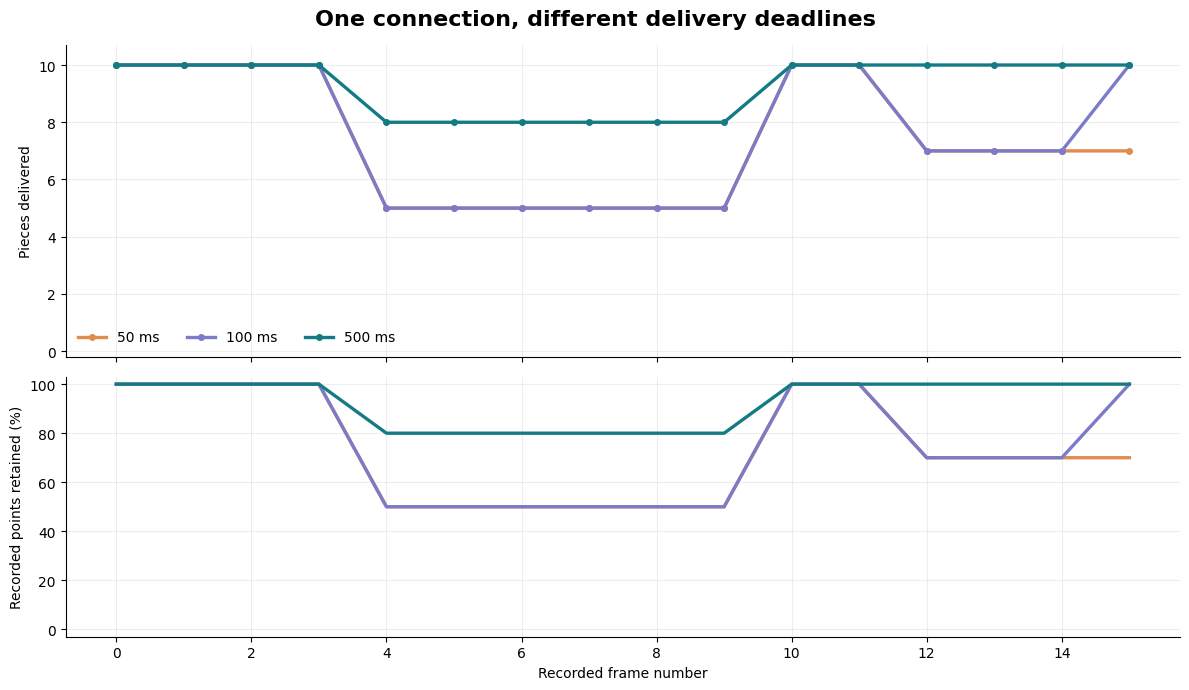

In [9]:
x = np.arange(N_FRAMES)
fig, ax = plt.subplots(2,1,figsize=(12,7),sharex=True,
                       gridspec_kw=dict(height_ratios=[1.2,1]))
palette = {50:ORANGE,100:"#7b7cc9",500:OCEAN}
for ms in DEADLINES_MS:
    ax[0].plot(x, SUMMARY[ms]["per_frame"], label=f"{ms} ms",
               linewidth=2.4, marker="o", markersize=4, color=palette[ms])
    ax[1].plot(x, 100*SUMMARY[ms]["point_fraction"], label=f"{ms} ms",
               linewidth=2.4, color=palette[ms])
ax[0].set_ylabel("Pieces delivered")
ax[0].set_ylim(-.2, TRACKS+.7)
ax[0].legend(frameon=False, ncol=3)
ax[1].set_ylabel("Recorded points retained (%)")
ax[1].set_xlabel("Recorded frame number")
ax[1].set_ylim(-3,103)
for a in ax:
    a.grid(alpha=.22)
    a.spines[["top","right"]].set_visible(False)
fig.suptitle("One connection, different delivery deadlines", fontsize=16, weight="bold")
plt.tight_layout(); plt.show()

## 8. Decode and rebuild the frames

Here is where compression meets the experience of the viewer: **only the Draco pieces actually delivered before the deadline are decoded and joined.**

The three panels share the same recorded frame and the same viewpoint. The only difference is which compressed objects the model delivered.

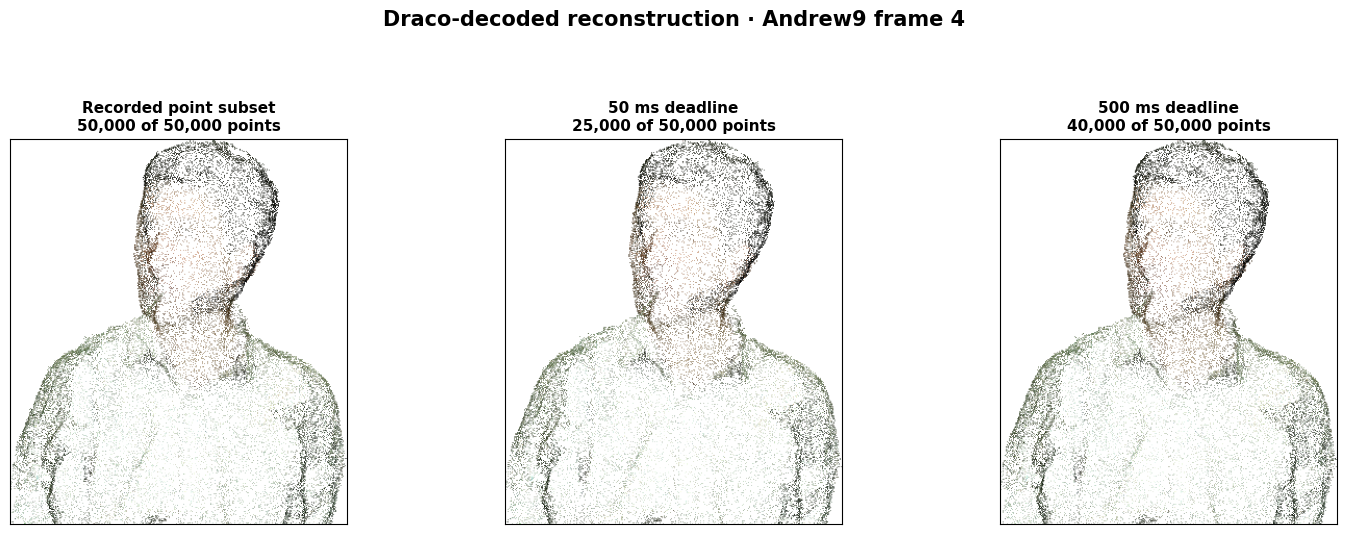

50 ms: 25,000 decoded points (50.0%)
500 ms: 40,000 decoded points (80.0%)


In [10]:
def reconstruct_frame(frame_id, result, object_by_key=OBJECT_BY_KEY):
    points, colors = [], []
    for track in range(TRACKS):
        key = (frame_id,track)
        if key in result["received"] and key in object_by_key:
            p, c = draco_decode(object_by_key[key].data)
            points.append(p); colors.append(c)
    if not points:
        return np.empty((0,3)), np.empty((0,3),dtype=np.uint8)
    return np.concatenate(points), np.concatenate(colors)

# choose a frame where the two deadlines differ most
diff = SUMMARY[500]["point_fraction"] - SUMMARY[50]["point_fraction"]
COMPARE_FRAME = int(np.argmax(diff)) if np.max(diff)>0 else VIEW_FRAME

reference_xyz, reference_rgb = FRAMES[COMPARE_FRAME]
plot_variants = [
    ("Recorded point subset",reference_xyz,reference_rgb),
    ("50 ms deadline",*reconstruct_frame(COMPARE_FRAME,RESULTS[50])),
    ("500 ms deadline",*reconstruct_frame(COMPARE_FRAME,RESULTS[500]))
]
fig, axes = plt.subplots(1,3,figsize=(15,5.4))
lims_x = (np.min(reference_xyz[:,HORIZONTAL_AXIS]), np.max(reference_xyz[:,HORIZONTAL_AXIS]))
lims_y = (np.min(reference_xyz[:,VERTICAL_AXIS]), np.max(reference_xyz[:,VERTICAL_AXIS]))
for ax, (title, points, colors) in zip(axes,plot_variants):
    if len(points):
        indices = np.random.default_rng(3).choice(
            len(points), min(28_000,len(points)), replace=False)
        ax.scatter(points[indices,HORIZONTAL_AXIS],points[indices,VERTICAL_AXIS],
                   c=colors[indices]/255, s=.4, linewidths=0)
    ax.set_xlim(*lims_x); ax.set_ylim(*lims_y)

    ax.set_aspect("equal")
    ax.set_title(f"{title}\n{len(points):,} of {len(reference_xyz):,} points",
                 fontweight="bold",fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Draco-decoded reconstruction · Andrew9 frame {COMPARE_FRAME}",
             fontweight="bold", fontsize=15)
plt.tight_layout(rect=[0,0,1,0.88]); plt.show()

for ms in (50,500):
    p,_=reconstruct_frame(COMPARE_FRAME,RESULTS[ms])
    print(f"{ms} ms: {len(p):,} decoded points ({len(p)/len(reference_xyz)*100:.1f}%)")

## 9. Protect the important region

The paper also explores prioritizing a person's head. Here I use a **simple, visible geometric rule**: points in the top 18% of the frame go into earlier, higher-priority pieces.

This small experiment shows how the *same number of available pieces* can retain more points near the top of the person.

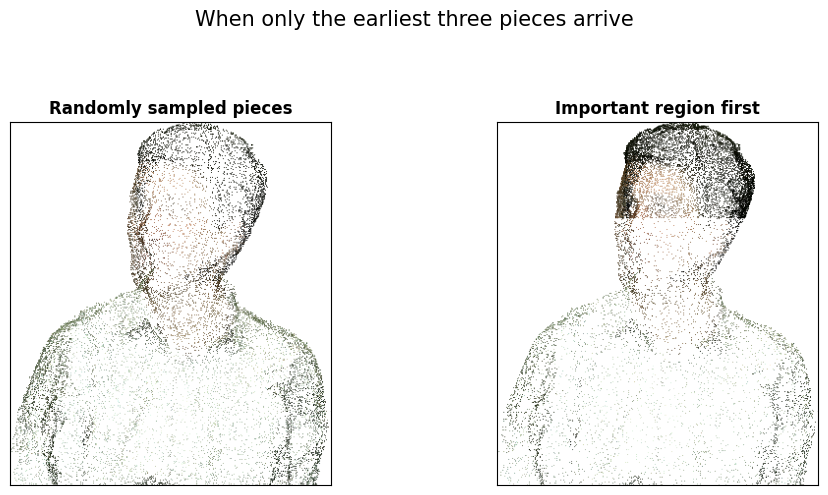

Top-region points retained, random: 2,736/9,091 (30.1%)
Top-region points retained, prioritized: 9,091/9,091 (100.0%)
Controlled selection demonstration only; not a network or PointNet evaluation.


In [11]:
focus_xyz, focus_rgb = FRAMES[VIEW_FRAME]
plain = RANDOM_INDEX_PARTITIONS[VIEW_FRAME]
aware = split_frame(focus_xyz, focus_rgb, VIEW_FRAME, salient_first=True)
upper_limit = np.quantile(focus_xyz[:,VERTICAL_AXIS],.82)
head_mask = focus_xyz[:,VERTICAL_AXIS] >= upper_limit

# a controlled comparison: the first three independently decodable pieces
count_early = 3
plain_idx = np.concatenate(plain[:count_early])
aware_idx = np.concatenate(aware[:count_early])
plain_head = int(head_mask[plain_idx].sum())
aware_head = int(head_mask[aware_idx].sum())
total_head = int(head_mask.sum())

fig,axs=plt.subplots(1,2,figsize=(10,5))
for ax,ids,name in zip(axs,[plain_idx,aware_idx],
                       ["Randomly sampled pieces","Important region first"]):
    ax.scatter(focus_xyz[ids,HORIZONTAL_AXIS],focus_xyz[ids,VERTICAL_AXIS],
               c=focus_rgb[ids]/255,s=.55,linewidths=0)
    ax.set_xlim(np.min(focus_xyz[:,HORIZONTAL_AXIS]),np.max(focus_xyz[:,HORIZONTAL_AXIS]))
    ax.set_ylim(np.min(focus_xyz[:,VERTICAL_AXIS]),np.max(focus_xyz[:,VERTICAL_AXIS]))
    ax.set_aspect("equal"); ax.set_xticks([]);ax.set_yticks([])
    ax.set_title(name,fontsize=12,weight="bold")
fig.suptitle("When only the earliest three pieces arrive",fontsize=15)
plt.tight_layout(rect=[0,0,1,0.9]);plt.show()

print(f"Top-region points retained, random: {plain_head:,}/{total_head:,} ({plain_head/total_head:.1%})")
print(f"Top-region points retained, prioritized: {aware_head:,}/{total_head:,} ({aware_head/total_head:.1%})")
print("Controlled selection demonstration only; not a network or PointNet evaluation.")

## 10. Verify the implementation

These checks confirm that no original point is counted twice within a partitioned frame, Draco actually decodes every sampled part, and received objects always meet their configured deadline.

In [12]:
# check complete partition coverage and unique point membership
for i,parts in enumerate(RANDOM_INDEX_PARTITIONS):
    indices = np.concatenate(parts)
    assert len(indices) == len(FRAMES[i][0])
    assert np.array_equal(np.sort(indices),np.arange(len(FRAMES[i][0])))

# verify a sample of genuine Draco objects, including color and point count
for obj in (OBJECTS[0],OBJECTS[len(OBJECTS)//2],OBJECTS[-1]):
    xyz,rgb=draco_decode(obj.data)
    assert xyz.shape==(obj.npoints,3)
    assert rgb.shape==(obj.npoints,3)

# confirm every delivered object was completed within its deadline
for ms,result in RESULTS.items():
    for key,completion in result["received"].items():
        assert completion <= OBJECT_BY_KEY[key].published_at + ms/1000.0 + 1e-8
        assert key not in result["dropped"]

print("PASS · Every selected real point belongs to exactly one piece.")
print("PASS · Genuine Draco payloads decode to point coordinates and RGB.")
print("PASS · No delivered object exceeds its configured deadline.")
print("PASS · All frames originate from the uploaded Andrew9 ZIP.")

PASS · Every selected real point belongs to exactly one piece.
PASS · Genuine Draco payloads decode to point coordinates and RGB.
PASS · No delivered object exceeds its configured deadline.
PASS · All frames originate from the uploaded Andrew9 ZIP.


---

## Summary

- **Real implementation:** MVUB frame loading, independent point partitions, genuine Draco encoding and decoding, frame assembly, and measurements.
- **Modeled mechanism:** A shared changing link, chunk-by-chunk delivery, expired-object drops, group resets, and simplified track ordering.
- **Not reproduced:** Live MoQ/QUIC protocol behavior, the paper's parallel encoding system, PointNet head segmentation, and the PCQM visual-quality metric.
- **Quality measure here:** Percentage of original recorded points recovered. It is **not** PCQM, VMAF, or a subjective visual-quality score.

The paper's main claim concerns **latency-driven implicit adaptation**: the receiver does not choose a fixed quality level; the amount of frame data arriving depends on the available network capacity and time allowance.

**Reference:** Freeman et al., *Point Cloud Streaming with Latency-Driven Implicit Adaptation using MoQ*, NOSSDAV 2026. [Paper](https://doi.org/10.1145/3798065.3798074) · [Google Draco](https://github.com/google/draco) · [DracoPy](https://github.com/seung-lab/DracoPy) · [MVUB dataset](https://plenodb.jpeg.org/pc/microsoft/)